# Mammalian cell cycle, growth signaling and apoptosis (Sizek et al.)

This notebook presents the stochastic simulations of the model of
[Sizek et al. (PLoS Comput Biol, 2019)](https://doi.org/10.1371/journal.pcbi.1006402), on the
[MaBoSS website](https://maboss.curie.fr). The model, with 87 nodes, integrates growth signaling, the regulatory
network controlling the mammalian cell cycle, and apoptosis.

The simulations are adapted from the tutorial of the CoLoMoTo software suite
([Noël et al., Interface Focus, 2025](https://doi.org/10.1098/rsfs.2025.0002)). The
[complete tutorial notebook](https://github.com/colomoto/colomoto-tutorial-sizek) also covers the analysis of
this model with other tools (GINsim, bioLQM, BNS...).

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/) with an executable of MaBoSS supporting more than
64 nodes (such as `MaBoSS_128n`) and [pygraphviz](https://pygraphviz.github.io/), all provided by the conda package
(`conda install -c colomoto pymaboss`), and the files
`CellCycleControl_Sizek_PCB_2019.bnd` and `CellCycleControl_Sizek_PCB_2019.cfg`, in the same folder as this
notebook. These files were obtained by converting the
[model of the GINsim repository](https://ginsim.github.io/models/2019-mammal-cell-cycle-control/) with bioLQM.

In [1]:
import os
import maboss
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Common style for the figures of the MaBoSS website notebooks
COLORS = ["#FF7F00", "#1F77B4", "#2CA02C", "#D62728", "#9467BD",
          "#8C564B", "#E377C2", "#17BECF", "#BCBD22", "#7F7F7F"]
mpl.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.prop_cycle": mpl.cycler(color=COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "legend.frameon": False,
    "lines.linewidth": 2,
})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    """Save a figure in the figures folder."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"))

def state_label(state):
    """Readable label for a MaBoSS state."""
    return "none active" if state == "<nil>" else state.replace(" -- ", ", ")

def pie(probas, ax, title=None, min_proba=0.01, labels=None):
    """Pie chart of a distribution; probabilities below min_proba are grouped as 'others'."""
    probas = pd.Series(probas).sort_values(ascending=False)
    small = probas[probas < min_proba]
    probas = probas[probas >= min_proba]
    if len(small) > 0:
        probas["others"] = small.sum()
    names = [labels.get(s, state_label(s)) if labels else state_label(s) for s in probas.index]
    colors = [COLORS[i % len(COLORS)] if s != "others" else "#D9D9D9" for i, s in enumerate(probas.index)]
    wedges, _ = ax.pie(probas.values, colors=colors, startangle=90, counterclock=False,
                       wedgeprops={"linewidth": 1, "edgecolor": "white"})
    ax.legend(wedges, [f"{n} ({p:.1%})" for n, p in zip(names, probas.values)],
              loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_aspect("equal")
    if title:
        ax.set_title(title)

def set_refstate_all(sim, value=0):
    """Give a reference state to every node.

    With MaBoSS 2.6.6, the states of the stationary distributions only include the nodes
    having a reference state; this makes them include all the nodes, as in previous versions.
    """
    for node in sim.network:
        if node not in sim.refstate:
            sim.refstate[node] = value

ipylab module is not installed, menus and toolbar are disabled.


We use a common color for each state in all the figures, and define functions to plot the results.

In [2]:
STATE_COLORS = {}
PALETTE = COLORS + ["#AEC7E8", "#FFBB78", "#98DF8A", "#FF9896", "#C5B0D5", "#C49C94", "#F7B6D2", "#9EDAE5",
                    "#DBDB8D", "#393B79", "#637939", "#8C6D31", "#843C39", "#7B4173"]

def state_color(state):
    if state == "<nil>":
        return "#D9D9D9"
    if state not in STATE_COLORS:
        STATE_COLORS[state] = PALETTE[len(STATE_COLORS) % len(PALETTE)]
    return STATE_COLORS[state]

def plot_nodes(result, ax, title, nodes=None):
    """Trajectories of the probabilities of the output nodes."""
    trajectories = result.get_nodes_probtraj()
    for node in (nodes or trajectories.columns):
        ax.plot(trajectories.index, trajectories[node], label=node, color=state_color(node))
    ax.set_xlabel("Time")
    ax.set_ylabel("Probability")
    ax.set_title(title)
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9)

def plot_overview(result, title):
    """Node trajectories, state trajectories, final states and entropies of a simulation."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    plot_nodes(result, axes[0, 0], "Node probabilities")

    states = result.get_states_probtraj()
    main = states.columns[states.max() >= 0.05]
    for state in main:
        axes[0, 1].plot(states.index, states[state], label=state_label(state), color=state_color(state))
    axes[0, 1].set_xlabel("Time")
    axes[0, 1].set_ylabel("Probability")
    axes[0, 1].set_title("State probabilities (states above 5%)")
    axes[0, 1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9)

    final = result.get_last_states_probtraj().iloc[0]
    final = final[final > 0].sort_values(ascending=False)
    small = final[final < 0.02]
    final = final[final >= 0.02]
    if small.sum() >= 0.001:
        final["others"] = small.sum()
    wedges, _ = axes[1, 0].pie(final.values, startangle=90, counterclock=False,
                               colors=[state_color(s) if s != "others" else "#F2F2F2" for s in final.index],
                               wedgeprops={"linewidth": 1, "edgecolor": "white"})
    axes[1, 0].legend(wedges, [f"{state_label(s) if s != 'others' else 'others'} ({p:.1%})" for s, p in final.items()],
                      loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9)
    axes[1, 0].set_title("Final states")

    entropy = result.get_entropy_trajectory()
    axes[1, 1].plot(entropy.index, entropy["TH"], label="Transition entropy (TH)")
    axes[1, 1].plot(entropy.index, entropy["H"], label="Entropy (H)")
    axes[1, 1].set_xlabel("Time")
    axes[1, 1].set_ylabel("Entropy")
    axes[1, 1].set_title("Entropies")
    axes[1, 1].legend()
    fig.suptitle(title, fontweight="bold", fontsize=14)
    fig.tight_layout()
    return fig

## The model

The model was exported from GINsim with all the initial values set to 0. We set the simulation parameters used in
the tutorial: 5000 trajectories, up to time 200, with a time window of 0.5. For reproducibility, we use the
pseudo-random generator, and 4 threads.

In [3]:
model = maboss.load("CellCycleControl_Sizek_PCB_2019.bnd", "CellCycleControl_Sizek_PCB_2019.cfg")
model.update_parameters(sample_count=5000, max_time=200, time_tick=0.5, use_physrandgen=0, thread_count=4)
print(len(model.network), "nodes")

87 nodes


We select the output nodes, i.e. the nodes reported in the results, and set the initial state defined by Sizek
et al. in their figure 6.

In [4]:
init_active = ["AKT_B", "BCL2", "BCLXL", "Cdc20", "Cdc25A", "Cdc25B", "Cdc25C", "Cdh1", "CyclinA_mRNA", "CyclinD1",
               "E2F1", "ERK", "Emi1", "GF", "GF_High", "Grb2", "IAPs", "MCL_1", "MEK", "Myc", "ORC", "PDK1", "PI3K",
               "PIP3", "Plk1_H", "RAF", "RTK", "Ras", "S6K", "SOS", "TSC2", "UbcH10", "eIF4E", "f4N_DNA", "mTORC1",
               "mTORC2", "pAPC"]

WT = model.copy()
WT.network.set_output(("CyclinB", "Casp3", "PI3K_H", "E2F1", "Replication", "p21", "RTK"))
maboss.set_nodes_istate(WT, init_active, [0, 1])

## Wild type

The simulations reveal a transient cyclic-like behaviour, which is eventually lost due to the spontaneous
activation of Casp3, revealing the progressive dominance of the apoptotic stable state. The entropy first rises
abruptly, then slowly decreases, while the transition entropy shows a small peak before remaining close to zero:
this suggests a transient periodic behaviour, which collapses as more and more cells trigger apoptosis.

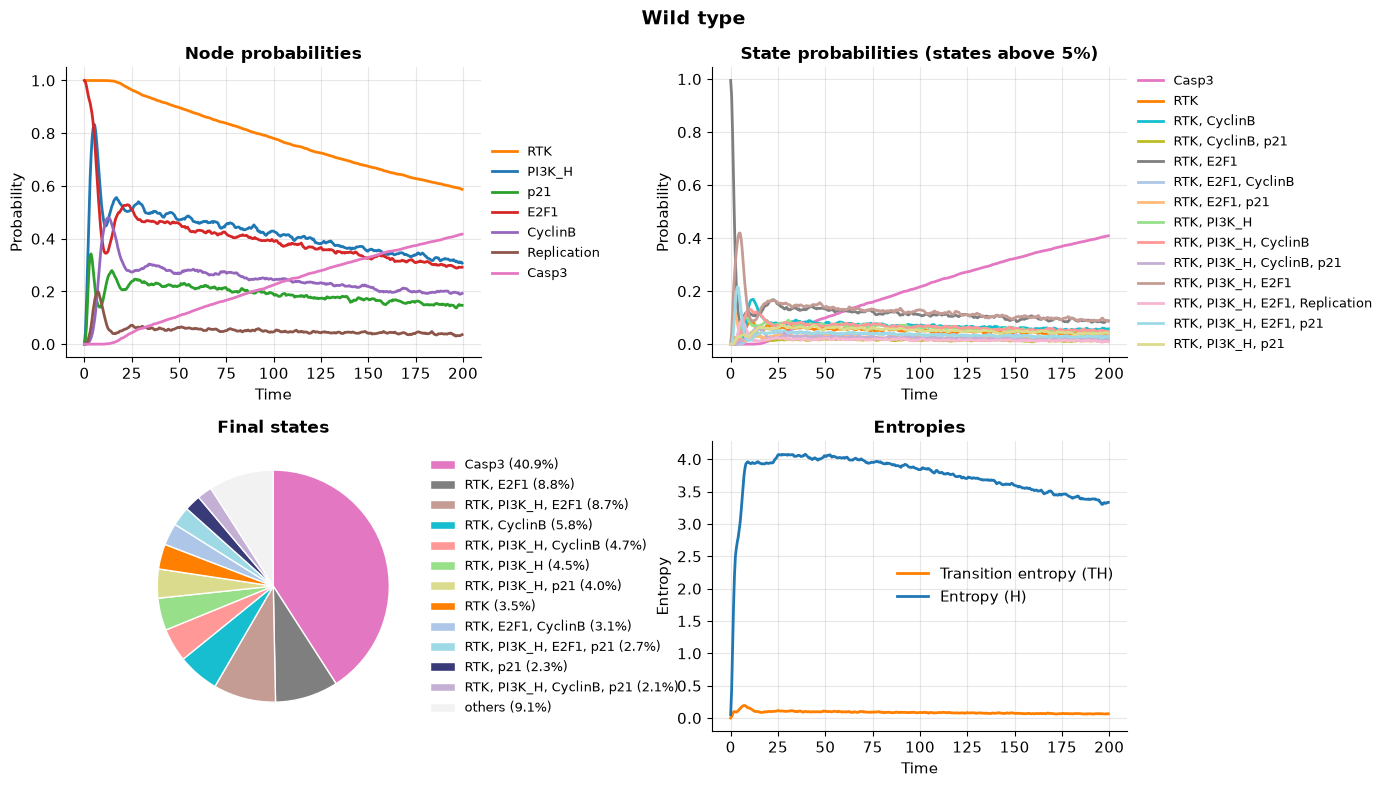

In [5]:
result_WT = WT.run()
fig = plot_overview(result_WT, "Wild type")
save(fig, "sizek_wt")

## Death signal

TRAIL is a ligand binding to death receptors and initiating the death pathways. With TRAIL active at the initial
state, Casp3, and thus apoptosis, rise much faster. The entropy drops faster, and the transition entropy stays
around zero, suggesting a stable state.

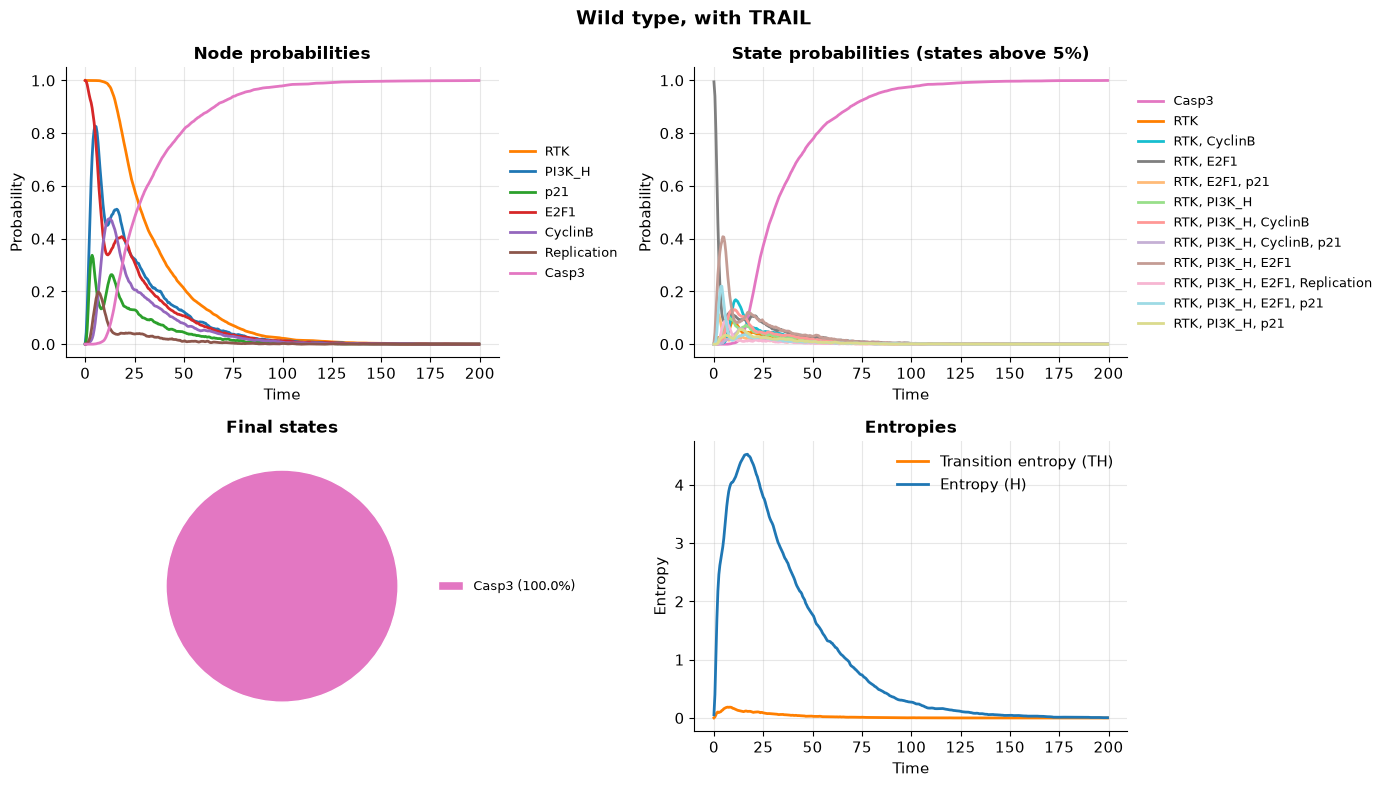

In [6]:
WT_death = WT.copy()
maboss.set_nodes_istate(WT_death, ["Trail"] + init_active, [0, 1])
result_death = WT_death.run()
fig = plot_overview(result_death, "Wild type, with TRAIL")
save(fig, "sizek_trail")

## Casp8 mutants

Casp8 is a caspase initiating the apoptotic cascade. Its ectopic activity drives the cells into apoptosis faster.
On the contrary, when Casp8 is knocked down, Casp3 is ultimately activated, as in the wild type: in this model,
apoptosis can occur even without Casp8.

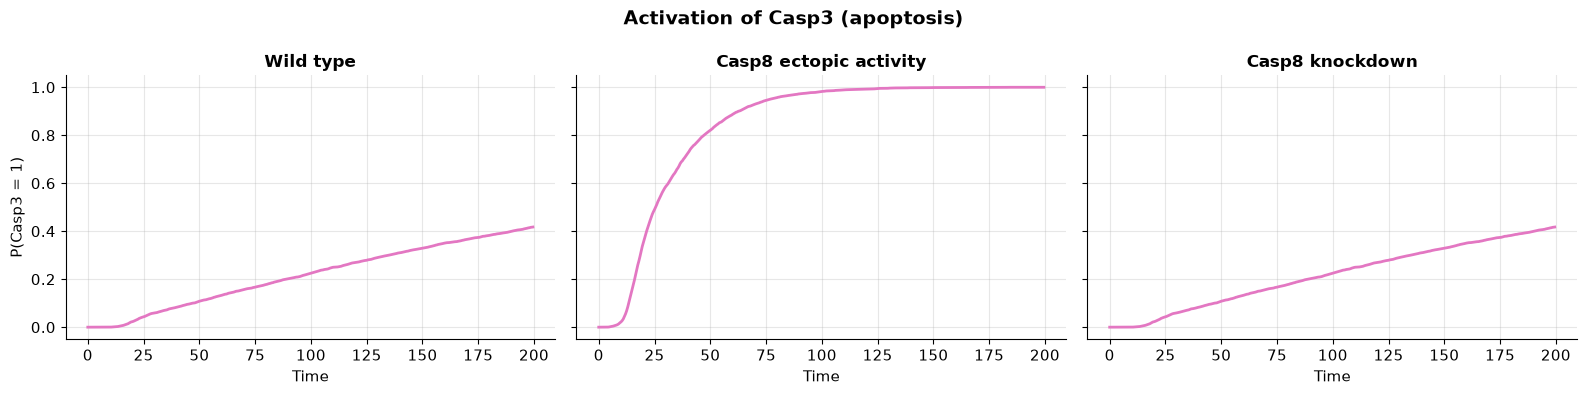

In [7]:
casp8_on = WT.copy()
casp8_on.mutate("Casp8", "ON")
casp8_off = WT.copy()
casp8_off.mutate("Casp8", "OFF")
result_casp8_on = casp8_on.run()
result_casp8_off = casp8_off.run()

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (title, result) in zip(axes, [("Wild type", result_WT), ("Casp8 ectopic activity", result_casp8_on),
                                      ("Casp8 knockdown", result_casp8_off)]):
    ax.plot(result.get_nodes_probtraj().index, result.get_nodes_probtraj()["Casp3"], color=state_color("Casp3"))
    ax.set_title(title)
    ax.set_xlabel("Time")
axes[0].set_ylabel("P(Casp3 = 1)")
fig.suptitle("Activation of Casp3 (apoptosis)", fontweight="bold", fontsize=14)
fig.tight_layout()
save(fig, "sizek_casp8")

## Screening of mutants

We simulate the loss-of-function and the ectopic activation of five nodes, and look for the mutants blocking
apoptosis (Casp3 activity below 1%) while keeping the cell cycle active (CyclinE activity above 15%): such
mutants correspond to a highly proliferative phenotype.

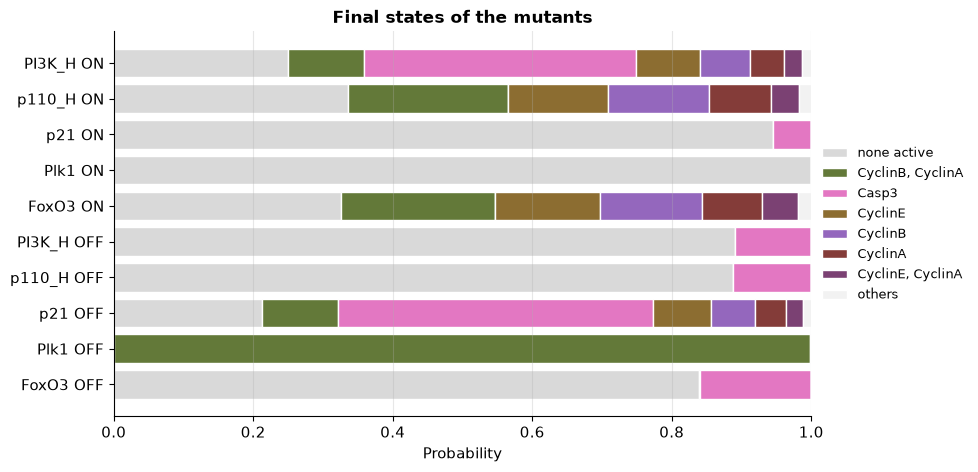

In [8]:
from maboss.pipelines import simulate_single_mutants, filter_sensitivity

explore = WT.copy()
explore.network.set_output(["Casp3", "CyclinA", "CyclinB", "CyclinE"])
mutants = simulate_single_mutants(explore, ["PI3K_H", "p110_H", "p21", "Plk1", "FoxO3"], sign="BOTH")

final = pd.concat([r.get_last_states_probtraj().set_axis([f"{node} {sign}"]) for (node, sign), r in mutants.items()]).fillna(0)
final = final[final.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 5))
left = np.zeros(len(final))
main = [s for s in final.columns if final[s].max() >= 0.02]
table = final[main].assign(others=final.drop(columns=main).sum(axis=1))
for state in table.columns:
    ax.barh(table.index, table[state], left=left, edgecolor="white",
            color="#F2F2F2" if state == "others" else state_color(state),
            label=state_label(state) if state != "others" else "others")
    left += table[state].values
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Probability")
ax.set_title("Final states of the mutants")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9)
save(fig, "sizek_mutants")

Mutants blocking apoptosis while keeping the cell cycle: p110_H ON, FoxO3 ON


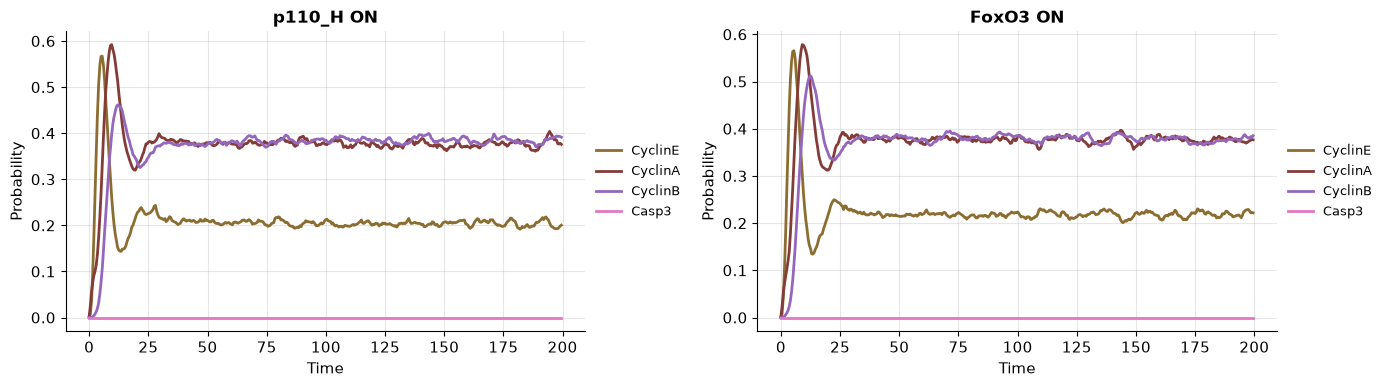

In [9]:
selected = filter_sensitivity(mutants, node="Casp3", maximum=0.01)
selected = filter_sensitivity(selected, node="CyclinE", minimum=0.15)
print("Mutants blocking apoptosis while keeping the cell cycle:",
      ", ".join(f"{node} {sign}" for node, sign in selected))

fig, axes = plt.subplots(1, len(selected), figsize=(7 * len(selected), 4), squeeze=False)
for ax, ((node, sign), result) in zip(axes[0], selected.items()):
    plot_nodes(result, ax, f"{node} {sign}")
fig.tight_layout()
save(fig, "sizek_mutants_selected")

Both the sustained activations of p110 and FoxO3 turn off Casp3, while maintaining the cell cycle.

## Order of activation of the cyclins

In the wild type, the cyclins should be activated in the following order: CyclinE, then CyclinA, then CyclinB,
and inactivated in the same order. The probabilities show the expected sequence of peaks; as MaBoSS reports
mean probabilities over many trajectories, these oscillations are rapidly damped.

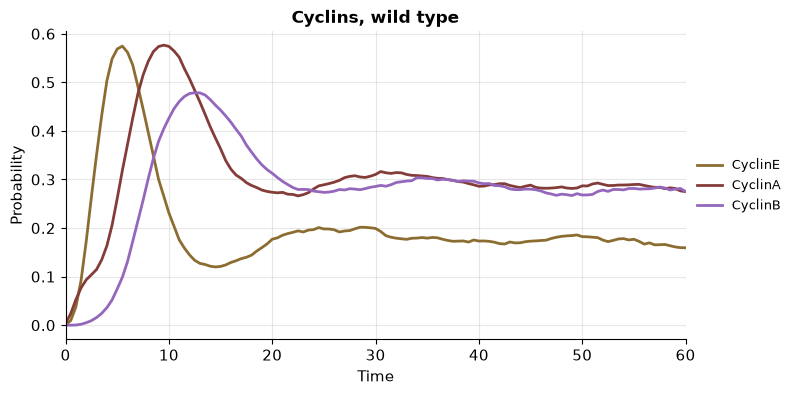

In [10]:
cyclins = ["CyclinE", "CyclinA", "CyclinB"]
WT_cyclins = WT.copy()
WT_cyclins.network.set_output(cyclins)
WT_cyclins.network.set_observed_graph_nodes(cyclins)
result_cyclins = WT_cyclins.run()

fig, ax = plt.subplots(figsize=(8, 4))
plot_nodes(result_cyclins, ax, "Cyclins, wild type", nodes=cyclins)
ax.set_xlim(0, 60)
save(fig, "sizek_cyclins")

MaBoSS can also estimate the frequencies of the transitions between the activity patterns of selected nodes,
over all the individual trajectories, and plot them as a *compressed state transition graph*: the darker the
arrow, the more probable the transition.

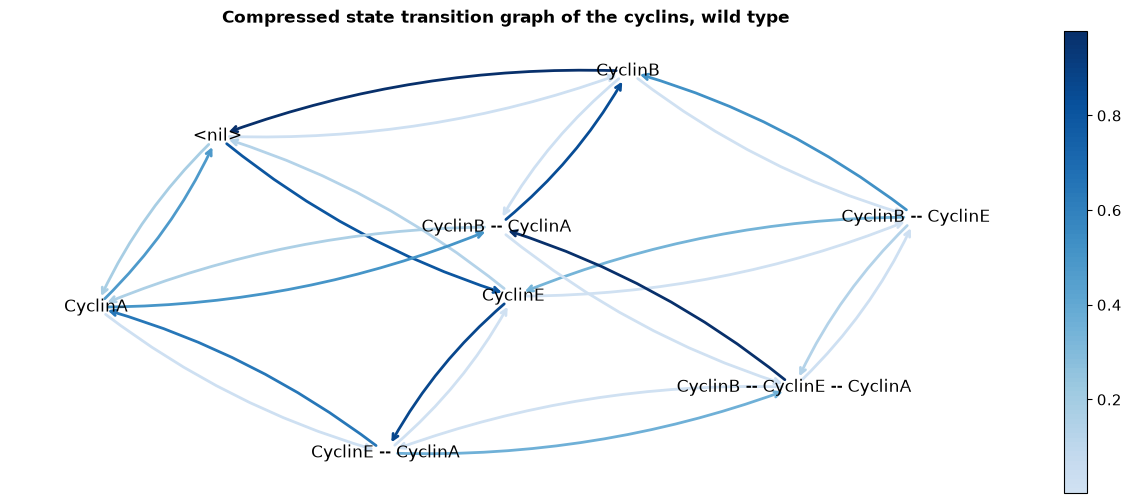

In [11]:
fig, ax = plt.subplots(1, 1, figsize=(16, 6))
result_cyclins.plot_observed_graph(axes=ax)
ax.set_title("Compressed state transition graph of the cyclins, wild type")
save(fig, "sizek_cyclins_graph")

Starting from the state without active cyclin (G0), the most probable sequence of transitions successively involves
the activation of CyclinE, the activation of CyclinA, the inactivation of CyclinE, the activation of CyclinB,
the inactivation of CyclinA, and finally the inactivation of CyclinB, completing the cycle. Other cycles are
followed with lower probabilities.

## Timing of apoptosis along the cell cycle

We add Casp3 to the observed nodes, to see at which point of the cell cycle apoptosis is triggered, in the wild
type and when p110 is constantly active. The transitions with a probability below 2% are not shown.

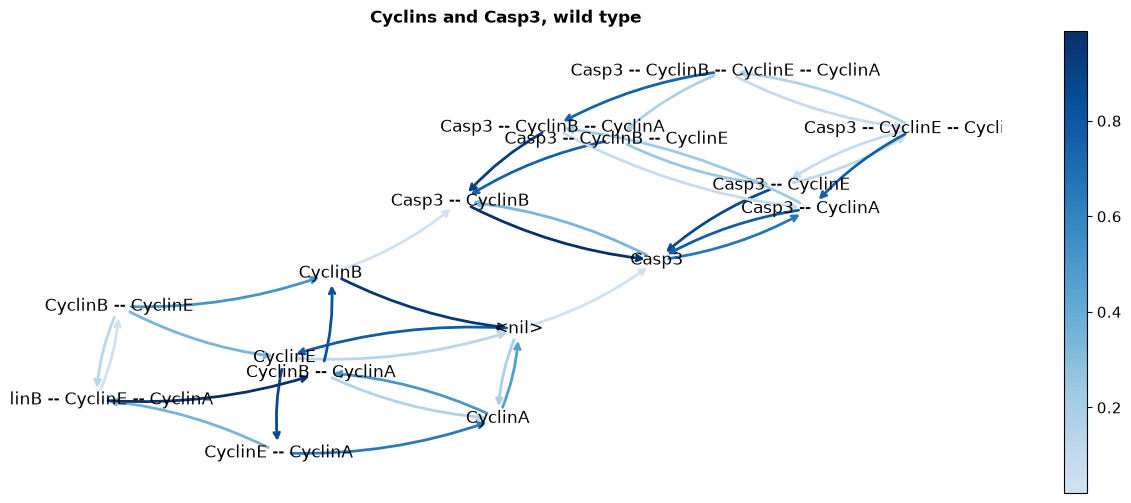

In [12]:
def casp3_graph(model, title, name):
    m = model.copy()
    nodes = ["Casp3"] + cyclins
    m.network.set_output(nodes)
    m.network.set_observed_graph_nodes(nodes)
    result = m.run()
    fig, ax = plt.subplots(1, 1, figsize=(16, 6))
    result.plot_observed_graph(axes=ax, prob_cutoff=0.02)
    ax.set_title(title)
    save(fig, name)
    return result

result_casp3 = casp3_graph(WT, "Cyclins and Casp3, wild type", "sizek_casp3_graph")

There are two main ways to activate apoptosis: from the state without active cyclin, which presumably represents
G0, and from the state where only CyclinB is active, which tentatively represents the G2/M phase.

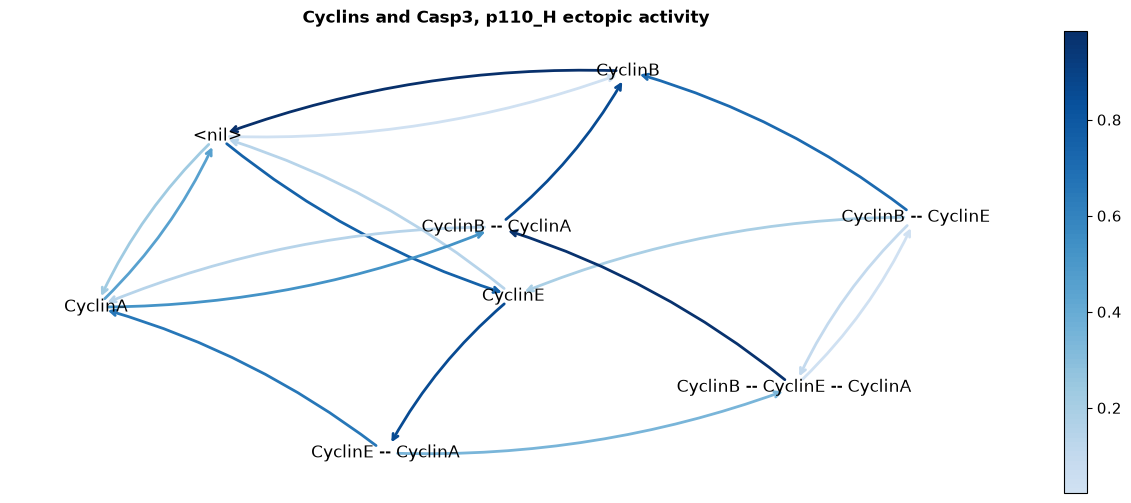

In [13]:
p110 = WT.copy()
p110.mutate("p110_H", "ON")
result_p110 = casp3_graph(p110, "Cyclins and Casp3, p110_H ectopic activity", "sizek_p110_graph")

The ectopic activity of p110_H completely disables the activation of apoptosis, and maintains the oscillatory
behaviour.